# 04. 듀오링고 신규 사용자 퍼널 분석

## 분석 목적

첫 레슨을 시작한 신규 사용자가 어느 단계에서 이탈하는지 확인하고, 첫 레슨 완료와 두 번째 레슨 시작의 개선 우선순위 파악.

- 입력: 02번에서 전처리하고 03번에서 EDA를 진행한 사용자·이벤트 CSV
- 이번 분석: 5단계 도달자 수, 전환율·이탈률, 주요 이탈 구간
- 이후 분석: H1~H5 집단별 비교 및 가설 검증

> 가상 데이터 기반 결과이며, 실제 듀오링고 사용자 지표 또는 이탈 원인으로 해석하지 않음.


## 1. 라이브러리 및 데이터 호출

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

In [2]:
# 프로젝트 최상위 경로: 본인 PC의 GitHub 저장소 위치
# 실제 폴더 위치가 다른 경우 ROOT 경로만 수정
ROOT = Path(r"C:\Users\joon5\Documents\github\duolingo-funnel-analysis")

# 02_basic_eda.ipynb에서 저장한 전처리 데이터의 경로
DATA_PROCESSED_DIR = ROOT / "data" / "processed"
USER_PROCESSED_PATH = DATA_PROCESSED_DIR / "users_preprocessed.csv"
EVENT_PROCESSED_PATH = DATA_PROCESSED_DIR / "event_logs_preprocessed.csv"

# 원본이 아닌 전처리 완료 데이터 호출
# 날짜 컬럼은 읽으면서 datetime 자료형으로 변환
df_users = pd.read_csv(USER_PROCESSED_PATH, parse_dates=["first_seen_at"])
df_events = pd.read_csv(EVENT_PROCESSED_PATH, parse_dates=["event_time"])

print("사용자:", len(df_users), "명")
print("이벤트:", len(df_events), "건")

사용자: 10000 명
이벤트: 320705 건


## 2. 퍼널 집계 기준 및 분석 대상

사용자별 첫 레슨 시작을 기준으로 이전 단계에 도달한 사용자만 다음 단계에 포함하는 **순차 퍼널** 적용. 이벤트 발생 횟수 대신 사용자 수로 집계.

| 단계 | 도달 기준 | 시간 제한 |
| --- | --- | --- |
| 1. 첫 레슨 시작 | `lesson_number = 1`의 최초 `lesson_started` | 최초 시작 시각을 기준점으로 사용 |
| 2. 첫 답안 제출 | 첫 문제(`question_number = 1`)의 최초 `answer_submitted` | 첫 시작 후 24시간 이내 |
| 3. 진행률 50% | 2단계 이후의 최초 `lesson_halfway_reached` | 첫 시작 후 24시간 이내 |
| 4. 첫 레슨 완료 | 3단계 이후의 최초 `lesson_completed` | 첫 시작 후 24시간 이내 |
| 5. 두 번째 레슨 시작 | 4단계 이후 `lesson_number = 2`의 최초 `lesson_started` | 첫 완료 후 7일 이내 |

- 정답·오답 모두 답안 제출로 인정하며, `question_skipped`는 제출에 미포함
- 1~4단계는 같은 `lesson_attempt_id`로 연결. 현재 데이터는 사용자당 첫 레슨 시도 1개로 구성
- 경계 시각인 24시간·7일은 포함하며, 이전 단계보다 이른 이벤트는 제외
- 설계상 관측 종료일은 **2026-10-09**. 로그의 마지막 발생 시각을 관측 종료일로 간주하지 않음
- 첫 시작부터 24시간 + 7일의 관측 기간을 확보한 사용자만 포함하여, 관측 기간이 부족한 사용자를 이탈자로 세는 문제 방지


In [3]:
# 프로젝트에서 정한 관측 종료 시각 및 전환 인정 기간
OBSERVATION_END = pd.Timestamp("2026-10-09 23:59:59")
FIRST_LESSON_WINDOW = pd.Timedelta(hours=24)
SECOND_LESSON_WINDOW = pd.Timedelta(days=7)

# 사용자별 첫 레슨 최초 시작 이벤트 선택
first_starts = df_events[
    (df_events["event_name"] == "lesson_started") &
    (df_events["lesson_number"] == 1)
].sort_values(["user_id", "event_time", "event_id"])

first_starts = first_starts.drop_duplicates("user_id")
first_starts = first_starts[
    ["user_id", "lesson_attempt_id", "event_time"]
].rename(columns={"event_time": "first_started_at"})

# 첫 레슨 완료 제한과 이후 7일 관측을 모두 확보한 사용자 선택
observation_ready = (
    first_starts["first_started_at"] + FIRST_LESSON_WINDOW + SECOND_LESSON_WINDOW
) <= OBSERVATION_END

print("관측 기간 부족으로 제외된 사용자:", (~observation_ready).sum(), "명")
first_starts = first_starts[observation_ready].copy()

# 사용자 특성과 최초 시작 시각 연결
funnel_users = pd.merge(df_users, first_starts, on="user_id", how="inner")
funnel_users["first_lesson_deadline"] = (
    funnel_users["first_started_at"] + FIRST_LESSON_WINDOW
)

print("퍼널 분석 대상:", len(funnel_users), "명")


관측 기간 부족으로 제외된 사용자: 0 명
퍼널 분석 대상: 10000 명


## 3. 사용자별 퍼널 도달 시각 생성

먼저 첫 레슨의 같은 시도에 속하고, 최초 시작부터 24시간 이내에 발생한 이벤트 선택. 이후 각 단계에서 순서에 맞는 최초 이벤트 시각 연결.


In [4]:
# 첫 레슨 이벤트와 사용자별 기준 시각 연결
first_lesson_events = pd.merge(
    df_events[df_events["lesson_number"] == 1],
    funnel_users[
        ["user_id", "lesson_attempt_id", "first_started_at", "first_lesson_deadline"]
    ],
    on=["user_id", "lesson_attempt_id"],
    how="inner",
)

# 첫 시작 이후 24시간 이내의 이벤트만 유지
first_lesson_events = first_lesson_events[
    (first_lesson_events["event_time"] >= first_lesson_events["first_started_at"]) &
    (first_lesson_events["event_time"] <= first_lesson_events["first_lesson_deadline"])
].sort_values(["user_id", "event_time", "event_id"])


### 3.1 첫 답안 제출: 2단계

첫 문제의 답안 제출만 선택하고, 재시도가 있어도 사용자별 최초 제출 1건으로 집계. 현재 답안 제출 로그에는 `attempt_number` 값이 없으므로 이벤트 시각으로 최초 제출 선택.


In [5]:
# 첫 문제의 최초 답안 제출 시각 선택
first_answers = first_lesson_events[
    (first_lesson_events["event_name"] == "answer_submitted") &
    (first_lesson_events["question_number"] == 1)
].drop_duplicates("user_id")

first_answers = first_answers[["user_id", "event_time"]].rename(
    columns={"event_time": "first_answer_at"}
)

# 미도달 사용자를 유지하기 위한 left 결합
funnel_users = pd.merge(funnel_users, first_answers, on="user_id", how="left")


### 3.2 진행률 50%: 3단계

첫 답안을 제출한 이후의 50% 도달 이벤트 선택. 해당 이벤트에는 `progress_percent` 값이 없으므로 `lesson_halfway_reached` 이벤트 자체로 도달 여부 판정.


In [6]:
# 50% 도달 이벤트와 앞 단계의 도달 시각 연결
halfway_events = pd.merge(
    first_lesson_events[
        first_lesson_events["event_name"] == "lesson_halfway_reached"
    ],
    funnel_users[["user_id", "first_answer_at"]],
    on="user_id",
    how="inner",
)

# 첫 답안 제출보다 이른 기록 및 첫 답안 미제출 사용자 제외
halfway_events = halfway_events[
    halfway_events["event_time"] >= halfway_events["first_answer_at"]
].sort_values(["user_id", "event_time", "event_id"]).drop_duplicates("user_id")

halfway_times = halfway_events[["user_id", "event_time"]].rename(
    columns={"event_time": "halfway_at"}
)
funnel_users = pd.merge(funnel_users, halfway_times, on="user_id", how="left")


### 3.3 첫 레슨 완료: 4단계

50% 도달 이후의 완료 이벤트 선택. 완료 시 에너지 잔량은 이후 H3 분석에서 사용할 수 있도록 함께 보관.


In [7]:
# 완료 이벤트와 50% 도달 시각 연결
completion_events = pd.merge(
    first_lesson_events[
        first_lesson_events["event_name"] == "lesson_completed"
    ],
    funnel_users[["user_id", "halfway_at"]],
    on="user_id",
    how="inner",
)

# 50% 도달 이후의 유효한 최초 완료 기록 선택
completion_events = completion_events[
    completion_events["event_time"] >= completion_events["halfway_at"]
].sort_values(["user_id", "event_time", "event_id"]).drop_duplicates("user_id")

completion_times = completion_events[
    ["user_id", "event_time", "energy_remaining"]
].rename(columns={"event_time": "first_completed_at"})

funnel_users = pd.merge(funnel_users, completion_times, on="user_id", how="left")


### 3.4 두 번째 레슨 시작: 5단계

유효한 첫 레슨 완료 이후부터 7일 이내의 두 번째 레슨 시작 이벤트 선택. 같은 날 시작한 경우도 포함하므로, 이 지표는 다음 날 재방문율과 구분.


In [8]:
# 두 번째 레슨 시작 이벤트와 첫 완료 시각 연결
second_start_events = pd.merge(
    df_events.loc[
        (df_events["event_name"] == "lesson_started") &
        (df_events["lesson_number"] == 2),
        ["user_id", "event_id", "event_time"],
    ],
    funnel_users[["user_id", "first_completed_at"]],
    on="user_id",
    how="inner",
)

# 첫 완료 이후 7일 이내의 유효한 최초 시작 기록 선택
second_start_events = second_start_events[
    (second_start_events["event_time"] >= second_start_events["first_completed_at"]) &
    (second_start_events["event_time"] <=
     second_start_events["first_completed_at"] + SECOND_LESSON_WINDOW)
].sort_values(["user_id", "event_time", "event_id"]).drop_duplicates("user_id")

second_start_times = second_start_events[["user_id", "event_time"]].rename(
    columns={"event_time": "second_started_at"}
)
funnel_users = pd.merge(funnel_users, second_start_times, on="user_id", how="left")


## 4. 단계별 전환율·이탈률 계산

- **누적 도달률** = 해당 단계 도달자 ÷ 첫 레슨 시작자 × 100
- **직전 단계 전환율** = 해당 단계 도달자 ÷ 직전 단계 도달자 × 100
- **직전 단계 이탈자 수** = 직전 단계 도달자 − 해당 단계 도달자
- **직전 단계 이탈률** = 직전 단계 이탈자 ÷ 직전 단계 도달자 × 100

첫 단계에는 비교할 직전 단계가 없어 전환율·이탈률을 `-`로 표시. 여기서 이탈은 정해진 시간 안에 다음 단계로 진행하지 않은 상태이며, 앱 삭제나 영구 이탈 여부와 구분.


In [9]:
# 사용자별 단계 도달 여부 생성: 도달 True, 미도달 False
time_columns = [
    "first_started_at", "first_answer_at", "halfway_at",
    "first_completed_at", "second_started_at",
]
step_columns = ["step_1", "step_2", "step_3", "step_4", "step_5"]

for step_column, time_column in zip(step_columns, time_columns):
    funnel_users[step_column] = funnel_users[time_column].notna()

# 단계별 도달자 수 집계
step_counts = funnel_users[step_columns].sum().tolist()
funnel_summary = pd.DataFrame({
    "단계": [
        "1. 첫 레슨 시작", "2. 첫 답안 제출", "3. 진행률 50%",
        "4. 첫 레슨 완료", "5. 두 번째 레슨 시작",
    ],
    "도달자 수": step_counts,
})

# shift(1): 바로 앞 단계의 도달자 수 연결
previous_counts = funnel_summary["도달자 수"].shift(1)
funnel_summary["누적 도달률(%)"] = (
    funnel_summary["도달자 수"] / step_counts[0] * 100
)
funnel_summary["직전 단계 전환율(%)"] = (
    funnel_summary["도달자 수"] / previous_counts * 100
)
funnel_summary["직전 단계 이탈자 수"] = previous_counts - funnel_summary["도달자 수"]
funnel_summary["직전 단계 이탈률(%)"] = (
    funnel_summary["직전 단계 이탈자 수"] / previous_counts * 100
)

# 원본 집계표의 숫자 자료형을 유지하며 출력 화면에서만 빈칸 변경
display(funnel_summary.round(2).fillna("-"))


C:\Users\joon5\AppData\Local\Temp\ipykernel_48200\4129872864.py:35: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  display(funnel_summary.round(2).fillna("-"))


,단계,도달자 수,누적 도달률(%),직전 단계 전환율(%),직전 단계 이탈자 수,직전 단계 이탈률(%)
0,1. 첫 레슨 시작,10000,100.00,-,-,-
1,2. 첫 답안 제출,9226,92.26,92.26,774.0,7.74
2,3. 진행률 50%,7824,78.24,84.8,1402.0,15.2
3,4. 첫 레슨 완료,6485,64.85,82.89,1339.0,17.11
4,5. 두 번째 레슨 시작,2815,28.15,43.41,3670.0,56.59


### 4.1 프로젝트 핵심 지표

첫 레슨 완료 관련 지표의 분모는 **시작자**, 두 번째 레슨 시작 관련 지표의 분모는 **첫 레슨 완료자**로 구분.


In [10]:
# 단계별 도달자 수를 활용한 핵심 지표 계산
first_start_count = step_counts[0]
first_complete_count = step_counts[3]
second_start_count = step_counts[4]

kpi_summary = pd.DataFrame({
    "지표": ["첫 레슨 완료율", "첫 레슨 미완료율", "두 번째 레슨 시작률", "완료 후 미진행률"],
    "해당 사용자 수": [
        first_complete_count,
        first_start_count - first_complete_count,
        second_start_count,
        first_complete_count - second_start_count,
    ],
    "기준 사용자 수": [
        first_start_count, first_start_count, first_complete_count, first_complete_count,
    ],
})
kpi_summary["비율(%)"] = (
    kpi_summary["해당 사용자 수"] / kpi_summary["기준 사용자 수"] * 100
)
display(kpi_summary.round(2))


,지표,해당 사용자 수,기준 사용자 수,비율(%)
0,첫 레슨 완료율,6485,10000,64.85
1,첫 레슨 미완료율,3515,10000,35.15
2,두 번째 레슨 시작률,2815,6485,43.41
3,완료 후 미진행률,3670,6485,56.59


## 5. 퍼널과 이탈 구간 시각화

왼쪽은 최초 시작자 대비 누적 도달 규모, 오른쪽은 직전 단계 대비 이탈률 표시. 오른쪽 막대 끝에 이탈자 수도 함께 표시.

> 첫 레슨 내 단계는 시작 후 24시간, 완료 → 두 번째 시작은 완료 후 7일 기준. 관측 시간과 행동이 다르므로 별도의 개선 과제로 해석.


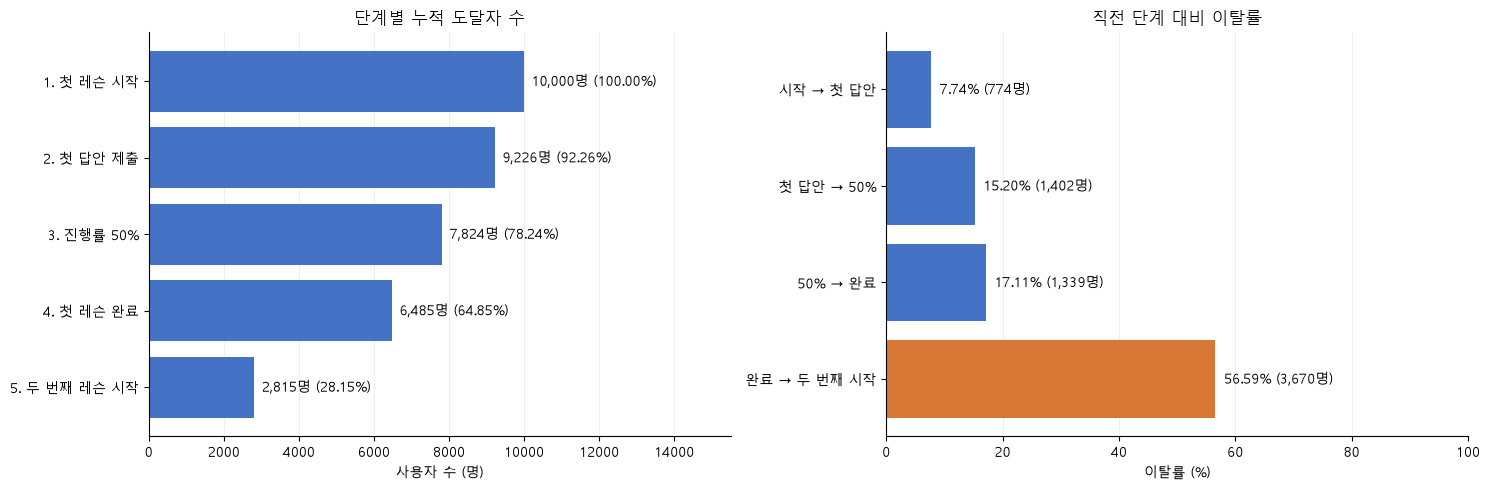

In [11]:
import matplotlib.pyplot as plt

# Windows 한글 글꼴 및 음수 기호 설정
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 앞에서 계산한 이탈 수치 재사용
dropoff_summary = funnel_summary.iloc[1:][
    ["직전 단계 이탈자 수", "직전 단계 이탈률(%)"]
].copy().reset_index(drop=True)
dropoff_summary["구간"] = [
    "시작 → 첫 답안", "첫 답안 → 50%", "50% → 완료", "완료 → 두 번째 시작",
]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 누적 도달자 수와 최초 시작자 대비 비율 표시
axes[0].barh(funnel_summary["단계"], funnel_summary["도달자 수"], color="#4472C4")
axes[0].invert_yaxis()
axes[0].set_xlim(0, first_start_count * 1.55)
axes[0].set_title("단계별 누적 도달자 수")
axes[0].set_xlabel("사용자 수 (명)")

for index, (count, rate) in enumerate(zip(
    funnel_summary["도달자 수"], funnel_summary["누적 도달률(%)"]
)):
    axes[0].text(count + first_start_count * 0.02, index,
                 f"{count:,}명 ({rate:.2f}%)", va="center")

# 구간별 이탈률과 이탈자 수 표시
axes[1].barh(
    dropoff_summary["구간"], dropoff_summary["직전 단계 이탈률(%)"],
    color=["#4472C4", "#4472C4", "#4472C4", "#D97736"],
)
axes[1].invert_yaxis()
axes[1].set_xlim(0, 100)
axes[1].set_title("직전 단계 대비 이탈률")
axes[1].set_xlabel("이탈률 (%)")

for index, (rate, count) in enumerate(zip(
    dropoff_summary["직전 단계 이탈률(%)"], dropoff_summary["직전 단계 이탈자 수"]
)):
    axes[1].text(rate + 1.5, index, f"{rate:.2f}% ({int(count):,}명)", va="center")

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()


## 6. 분석 결과 및 다음 확인 사항

### 6.1 전체 퍼널 결과

- 시작자 10,000명 중 첫 레슨 완료 **6,485명(64.85%)**, 미완료 **3,515명(35.15%)**.
- 완료자 6,485명 중 7일 이내 두 번째 레슨 시작 **2,815명(43.41%)**, 미진행 **3,670명(56.59%)**.
- 최초 시작자 10,000명 기준 두 번째 레슨까지의 누적 도달률 **28.15%**.

### 6.2 주요 이탈 구간

| 관점 | 구간 | 확인한 결과 | 후속 분석 방향 |
| --- | --- | --- | --- |
| 전체 구간 중 최대 이탈 | 첫 완료 → 두 번째 시작 | 완료자 중 3,670명, 56.59% 미진행 | H1 구독 안내·H3 에너지·H5 일일 목표별 후속 시작률 비교 |
| 첫 레슨 내부 최대 이탈 인원 | 첫 답안 → 50% | 1,402명 이탈, 직전 단계 대비 15.20% | 중반 도달 전의 오답·힌트·말하기 건너뛰기 경험 탐색 |
| 첫 레슨 내부 최고 이탈률 | 50% → 완료 | 1,339명 이탈, 직전 단계 대비 17.11% | 후반 진행 중 행동을 확인하고 H2·H4의 완료율 차이 비교 |

이탈 **인원**이 가장 많은 구간과 이탈 **비율**이 가장 높은 구간을 구분. 3단계까지 도달한 사용자를 대상으로 4단계 전환을 개선하는 문제와, 완료 후 후속 학습을 유도하는 문제를 각각 검토.

### 6.3 해석 범위

이번 분석으로 **이탈이 집중된 구간** 확인. 구독 안내, 말하기 건너뛰기, 에너지 부족 등이 이탈을 유발했는지는 아직 판단 불가. H1~H5 집단 비교를 통해 관련성을 확인하고, 가상 데이터의 생성 규칙과 행동 기회의 차이를 함께 고려할 필요.


## 7. 집계 결과 검증 및 저장

02번의 결측치·원본 ID 검사는 반복하지 않고, 새로 만든 퍼널 표의 사용자 단위·단계 순서·시간 제한만 마지막에 확인.


In [12]:
# 사용자 1명당 결과 1행 및 단계별 포함 관계 확인
assert funnel_users["user_id"].is_unique, "사용자별 퍼널 집계에 중복 존재"

for previous_step, next_step in zip(step_columns[:-1], step_columns[1:]):
    assert not (funnel_users[next_step] & ~funnel_users[previous_step]).any(), "단계 포함 관계 확인 필요"

# 각 단계의 도달 시각이 이전 단계보다 빠르지 않은지 확인
for previous_time, next_time in zip(time_columns[:-1], time_columns[1:]):
    reached = funnel_users[next_time].notna()
    assert (
        funnel_users.loc[reached, next_time] >= funnel_users.loc[reached, previous_time]
    ).all(), "이벤트 순서 확인 필요"

# 첫 완료 24시간 및 두 번째 시작 7일 제한 확인
completed = funnel_users["step_4"]
continued = funnel_users["step_5"]
assert (
    funnel_users.loc[completed, "first_completed_at"] <=
    funnel_users.loc[completed, "first_lesson_deadline"]
).all(), "첫 레슨 완료 시간 제한 확인 필요"
assert (
    funnel_users.loc[continued, "second_started_at"] <=
    funnel_users.loc[continued, "first_completed_at"] + SECOND_LESSON_WINDOW
).all(), "두 번째 레슨 시작 시간 제한 확인 필요"

print("퍼널 집계 검증 완료")


퍼널 집계 검증 완료


In [13]:
# 사용자별 도달 시각·단계 플래그 저장: 다음 가설 분석에서 재사용
FUNNEL_USERS_PATH = DATA_PROCESSED_DIR / "funnel_users.csv"

# 보고서 작성용 단계별 집계표 저장
REPORTS_DIR = ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
FUNNEL_SUMMARY_PATH = REPORTS_DIR / "funnel_summary.csv"

funnel_users.to_csv(FUNNEL_USERS_PATH, index=False, encoding="utf-8-sig")
funnel_summary.round(2).to_csv(FUNNEL_SUMMARY_PATH, index=False, encoding="utf-8-sig")

print("사용자별 퍼널 저장:", FUNNEL_USERS_PATH.relative_to(ROOT))
print("단계별 집계표 저장:", FUNNEL_SUMMARY_PATH.relative_to(ROOT))


사용자별 퍼널 저장: data\processed\funnel_users.csv
단계별 집계표 저장: reports\funnel_summary.csv


## 8. 다음 단계: H1~H5 가설 분석

`05_hypothesis_testing.ipynb`에서 저장한 `funnel_users.csv`와 전처리 이벤트를 활용해 집단별 전환율 비교 예정.

| 가설 | 분석 대상 | 비교 항목 | 결과 지표 |
| --- | --- | --- | --- |
| H1 | 첫 레슨 완료자 | 구독 안내 노출 여부 | 두 번째 레슨 시작률 |
| H2 | 첫 레슨 시작자 | 말하기 건너뛰기 여부 | 첫 레슨 완료율 |
| H3 | 첫 레슨 완료자 | 완료 시 에너지 0~5 / 6 이상 | 두 번째 레슨 시작률 |
| H4 | 첫 레슨 시작자, 오답 경험자 별도 비교 | 힌트 사용 여부 | 첫 레슨 완료율 |
| H5 | 첫 레슨 완료자 | 일일 목표 3 / 10 / 15 / 30분 | 두 번째 레슨 시작률 |

행동 경험은 결과보다 앞선 유효한 관측 구간에서 정의. H2는 말하기 문제를 경험할 기회, H4는 오답·힌트를 경험할 기회의 차이도 고려. 가설과 다른 방향이나 차이가 없는 결과도 그대로 기록.
